# Actividad 1: Análisis Exploratorio de Preferencias y Comportamiento del Consumidor

## Objetivo:
Aplicar técnicas de limpieza, visualización y análisis descriptivo para comprender patrones de consumo y perfiles de usuario en una base de datos real, desarrollando competencias en la manipulación de datos y la comunicación de hallazgos técnicos.

## Descripción:
Utilizando un conjunto de datos sobre transacciones comerciales adjunto en la actividad, los estudiantes realizarán un ciclo completo de Ciencia de Datos a nivel exploratorio que incluya depuración de datos, análisis visual, interpretación estadística y documentación de hallazgos.

### 1. Exploración Inicial

En esta sección realizamos la carga de datos y el diagnóstico inicial del dataset.

In [224]:
import pandas as pd

# Cargar el dataset
df = pd.read_csv('/content/dataset_ventas.csv')

# Diagnóstico inicial: número de filas y columnas
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.\n")

# Tipos de datos
print("Información de las columnas y tipos de datos:")
display(df.info())

# Vista previa de los primeros datos
print("\nVista previa de los primeros datos")
display(df.head())

# Vista de estadísticos básicos del dataframe
print("\nVista de estadísticos básicos del dataframe")
display(df.describe())

Dimensiones del dataset: 260 filas y 9 columnas.

Información de las columnas y tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Transaccion      260 non-null    object 
 1   Fecha               260 non-null    object 
 2   ID_Cliente          260 non-null    int64  
 3   Edad_Cliente        248 non-null    float64
 4   Categoria_Producto  260 non-null    object 
 5   Monto_Venta         252 non-null    float64
 6   Cantidad            260 non-null    int64  
 7   Metodo_Pago         260 non-null    object 
 8   Ciudad              214 non-null    object 
dtypes: float64(2), int64(2), object(5)
memory usage: 18.4+ KB


None


Vista previa de los primeros datos


,ID_Transaccion,Fecha,ID_Cliente,Edad_Cliente,Categoria_Producto,Monto_Venta,Cantidad,Metodo_Pago,Ciudad
0,TRX-1095,2023-04-06,5325,43.0,Juguetes,181.47,4,Efectivo,Valencia
1,TRX-1099,2023-04-10,5189,24.0,Deportes,190.32,4,PayPal,Barcelona
2,TRX-1006,2023-01-07,5114,54.0,Electrónica,490.75,1,Tarjeta de Crédito,Valencia
3,TRX-1153,2023-06-03,5073,65.0,Hogar,25.89,2,Transferencia,Bilbao
4,TRX-1087,2023-03-29,5040,47.0,Deportes,174.71,2,Tarjeta de Crédito,Madrid



Vista de estadísticos básicos del dataframe


,ID_Cliente,Edad_Cliente,Monto_Venta,Cantidad
count,260.000000,248.000000,252.000000,260.000000
mean,5245.003846,42.907258,595.668571,6.892308
std,144.420704,17.144642,5339.782528,61.780437
min,5000.000000,-10.000000,25.890000,1.000000
25%,5115.500000,29.000000,153.797500,2.000000
50%,5255.500000,43.000000,251.900000,3.000000
75%,5368.250000,55.000000,369.340000,4.000000
max,5498.000000,155.000000,85000.000000,999.000000


In [225]:
# Asegurarse de que df existe antes de procesar
try:
    numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
    categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

    print(f"Columnas Numéricas ({len(numeric_cols)}): {numeric_cols}")
    print(f"Columnas Categóricas ({len(categorical_cols)}): {categorical_cols}")
except NameError:
    print("Error: El DataFrame 'df' no está definido. Por favor, asegúrate de ejecutar primero la celda de carga de datos.")

Columnas Numéricas (4): ['ID_Cliente', 'Edad_Cliente', 'Monto_Venta', 'Cantidad']
Columnas Categóricas (5): ['ID_Transaccion', 'Fecha', 'Categoria_Producto', 'Metodo_Pago', 'Ciudad']


Del diagnóstico inicial podemos concluir lo siguiente:

* **Dimensiones**: El dataset cuenta con 260 registros y 9 columnas.
* **Variables Numéricas** (4): `ID_Cliente`, `Edad_Cliente`, `Monto_Venta` y `Cantidad`.
* **Variables Categóricas** (5): `ID_Transaccion`, `Fecha`, `Categoria_Producto`, `Metodo_Pago` y `Ciudad`.

También notamos que hay algunos valores faltantes (`NaN`) en columnas como `Edad_Cliente`, `Monto_Venta` y `Ciudad`, lo cual será importante para el siguiente paso de depuración de datos.

**NOTA**: Es importante notar que no se especifica el tipo de moneda en el monto transacción. Para el presente ejercicio se asume que son **Euros** (€) dadas las ciudades de la columna `Ciudad`

### 2. Limpieza de Datos

Calculamos el porcentaje de valores no nulos en cada columna para identificar la presencia de valores faltantes.

In [226]:
# Calcular el porcentaje de valores no nulos
porcentaje_no_nulos = (df.count() / len(df)) * 100

# Crear un DataFrame para mostrar los resultados de forma ordenada
resumen_integridad = pd.DataFrame({
    'Valores No Nulos': df.count(),
    'Porcentaje (%)': porcentaje_no_nulos.round(2)
})

print("Porcentaje de No nulos por columna:")
display(resumen_integridad)

Porcentaje de No nulos por columna:


,Valores No Nulos,Porcentaje (%)
ID_Transaccion,260,100.00
Fecha,260,100.00
ID_Cliente,260,100.00
Edad_Cliente,248,95.38
Categoria_Producto,260,100.00
Monto_Venta,252,96.92
Cantidad,260,100.00
Metodo_Pago,260,100.00
Ciudad,214,82.31


Convertimos la columna `Fecha` de tipo `object` (texto) a tipo `datetime` para facilitar su manipulación.

In [227]:
# Convertir la columna Fecha a tipo datetime
df['Fecha'] = pd.to_datetime(df['Fecha'])

# Verificar el cambio de tipo de dato
print(f"El nuevo tipo de dato de la columna 'Fecha' es: {df['Fecha'].dtype}")
display(df[['Fecha']].head())

El nuevo tipo de dato de la columna 'Fecha' es: datetime64[ns]


,Fecha
0,2023-04-06
1,2023-04-10
2,2023-01-07
3,2023-06-03
4,2023-03-29


#### 2.1 Detección de duplicados
En este paso identificamos si existen filas que se repiten exactamente en todo el dataset y evaluamos su impacto financiero.

In [228]:
# 1. Contar duplicados exactos
cantidad_duplicados = df.duplicated().sum()

# 2. Calcular impacto en ventas totales
ventas_con_duplicados = df['Monto_Venta'].sum()
df_sin_duplicados = df.drop_duplicates()
ventas_sin_duplicados = df_sin_duplicados['Monto_Venta'].sum()
impacto_ventas = ventas_con_duplicados - ventas_sin_duplicados

print(f"Cantidad de registros duplicados exactos: {cantidad_duplicados}\n")
print(f"Ventas totales con duplicados: €{ventas_con_duplicados:,.2f}")
print(f"Ventas totales sin duplicados: €{ventas_sin_duplicados:,.2f}\n")
print(f"Impacto (Sobreestimación de ventas): €{impacto_ventas:,.2f}")

# Eliminar los duplicados del DataFrame principal de forma permanente
df_original = df.copy()
df = df_sin_duplicados.copy()
print('\nSe han eliminado los duplicados del DataFrame principal.')

Cantidad de registros duplicados exactos: 9

Ventas totales con duplicados: €150,108.48
Ventas totales sin duplicados: €147,550.32

Impacto (Sobreestimación de ventas): €2,558.16

Se han eliminado los duplicados del DataFrame principal.


Existen 9 registros duplicados *exactos*.

El impacto de no eliminarlos sería una sobreestimación de las **Ventas Totales** por un valor de **€2,558.16**. Es fundamental realizar esta limpieza para asegurar que los análisis estadísticos posteriores no estén sesgados por datos redundantes.

#### 2.2 Tratamiento de valores nulos en la columna `Ciudad`
Evaluamos el impacto de eliminar los registros sin ciudad frente a la opción de imputarlos con una etiqueta genérica.

In [229]:
# Analizar registros con Ciudad nula
registros_ciudad_nula = df[df['Ciudad'].isna()]
cantidad_nulos_ciudad = len(registros_ciudad_nula)
ventas_nulos_ciudad = registros_ciudad_nula['Monto_Venta'].sum()
porcentaje_ventas_nulas = (ventas_nulos_ciudad / df['Monto_Venta'].sum()) * 100

print(f"Registros con Ciudad nula: {cantidad_nulos_ciudad}\n")
print(f"Monto de ventas asociado a Ciudad nula: €{ventas_nulos_ciudad:,.2f}")
print(f"Representa el {porcentaje_ventas_nulas:.2f}% de las ventas totales.")

# Aplicar la decisión: Etiquetar como 'No especificado'
df['Ciudad'] = df['Ciudad'].fillna('No especificado')

print('\nDecisión: Se han etiquetado los nulos como "No especificado" para evitar la pérdida del historial de ventas.')

Registros con Ciudad nula: 45

Monto de ventas asociado a Ciudad nula: €11,061.36
Representa el 7.50% de las ventas totales.

Decisión: Se han etiquetado los nulos como "No especificado" para evitar la pérdida del historial de ventas.


**Justificación:**
Se optó por **etiquetar los valores como "No especificado"** en lugar de eliminarlos porque la pérdida de información representaría una parte considerable de los registros y del volumen de ventas (€11,061.36, el 7.50% de las Ventas Totales).

Al mantener estos registros, conservamos datos valiosos en otras columnas como `Edad_Cliente` y `Monto_Venta` que siguen siendo útiles para el análisis de comportamiento general, aunque no podamos segmentarlos por ubicación geográfica exacta.

#### 2.3 Estandarización de Categorías
Identificamos y corregimos inconsistencias de formato (mayúsculas/minúsculas, espacios extra, tildes) en las variables categóricas para evitar duplicidad visual en los gráficos.

In [230]:
# 1. Inspeccionar valores únicos antes de estandarizar
print("Valores únicos en 'Metodo_Pago' antes:", df['Metodo_Pago'].unique())
print("Valores únicos en 'Categoria_Producto' antes:", df['Categoria_Producto'].unique())

# 2. Aplicar estandarización (Ejemplo: Capitalize y quitar espacios)
df['Metodo_Pago'] = df['Metodo_Pago'].str.strip().str.capitalize()
df['Categoria_Producto'] = df['Categoria_Producto'].str.strip().str.capitalize()

print("\nValores únicos en 'Metodo_Pago' después:", df['Metodo_Pago'].unique())
print("Valores únicos en 'Categoria_Producto' después:", df['Categoria_Producto'].unique())

Valores únicos en 'Metodo_Pago' antes: ['Efectivo' 'PayPal' 'Tarjeta de Crédito' 'Transferencia' 'tarjeta']
Valores únicos en 'Categoria_Producto' antes: ['Juguetes' 'Deportes' 'Electrónica' 'Hogar' 'Moda' 'electrónica']

Valores únicos en 'Metodo_Pago' después: ['Efectivo' 'Paypal' 'Tarjeta de crédito' 'Transferencia' 'Tarjeta']
Valores únicos en 'Categoria_Producto' después: ['Juguetes' 'Deportes' 'Electrónica' 'Hogar' 'Moda']


Se nota algo interesante en los resultados: en `Metodo_Pago` aún tenemos 'Tarjeta de crédito' y 'Tarjeta' como categorías separadas. Si hiciéramos un gráfico de barras ahora, veríamos dos barras distintas para lo que probablemente es el mismo medio de pago.

In [231]:
# Unificar las categorías de Tarjeta
df['Metodo_Pago'] = df['Metodo_Pago'].replace('Tarjeta', 'Tarjeta de crédito')

print("Valores únicos actualizados en 'Metodo_Pago':")
print(df['Metodo_Pago'].unique())

Valores únicos actualizados en 'Metodo_Pago':
['Efectivo' 'Paypal' 'Tarjeta de crédito' 'Transferencia']


**Impacto en Visualización:**
Si no se realizara esta limpieza, cualquier gráfico de barras (por ejemplo, Ventas por Categoría) presentaría una segmentación artificial. Esto fragmentaría el volumen real de datos en múltiples barras redundantes, impidiendo identificar correctamente la categoría líder o el método de pago más utilizado.

### 3. Análisis Estadístico y Outliers

En esta sección evaluamos la tendencia central de los datos y el impacto de valores extremos en la interpretación de los resultados.

In [232]:
import matplotlib.pyplot as plt

# Identificar y eliminar el outlier de 85,000
# Se filtra el dataframe para mantener solo ventas menores a un umbral lógico o eliminar ese valor específico
df = df[df['Monto_Venta'] != 85000]

# Recalcular media y mediana del Monto_Venta sin el outlier
media_venta = df['Monto_Venta'].mean()
mediana_venta = df['Monto_Venta'].median()
max_venta = df['Monto_Venta'].max()

print(f"--- Estadísticas después de eliminar el outlier --- ")
print(f"Media del Monto_Venta: €{media_venta:,.2f}")
print(f"Mediana del Monto_Venta: €{mediana_venta:,.2f}")
print(f"Nuevo valor máximo: €{max_venta:,.2f}")

--- Estadísticas después de eliminar el outlier --- 
Media del Monto_Venta: €258.47
Mediana del Monto_Venta: €249.15
Nuevo valor máximo: €498.53


**Análisis del Impacto de Valores Extremos:**

Existe una diferencia significativa entre la media y la mediana debido a la presencia de un **outlier extremo (€85,000)**.

*   **La Media** es muy sensible a valores atípicos, por lo que se eleva artificialmente, dando una falsa impresión de que el gasto promedio es mayor de lo que realmente es para la mayoría.
*   **La Mediana** representa mejor al "cliente promedio" en este caso, ya que es una medida robusta que no se ve afectada por valores extremos, indicando el punto central donde se encuentra el 50% de las transacciones.

#### 3.1 Validación de Rangos: Edad del Cliente
Identificamos valores biológicamente imposibles o fuera de contexto comercial en la columna `Edad_Cliente`.

In [233]:
# Identificar valores fuera de rango
edades_atipicas = df[(df['Edad_Cliente'] < 14) | (df['Edad_Cliente'] > 100)]
print(f"Registros con edades fuera de rango (<14 o >100): {len(edades_atipicas)}")
display(edades_atipicas[['ID_Cliente', 'Edad_Cliente']])



Registros con edades fuera de rango (<14 o >100): 2


,ID_Cliente,Edad_Cliente
14,5346,155.0
162,5125,-10.0


**Justificación:**
Un rango de edad válido se define entre **14 y 100 años** basándose en la naturaleza de las transacciones comerciales legales y la expectativa de vida humana.

*   **Valores negativos (-10):** Son errores de entrada de datos.
*   **Valores extremos (155):** Son biológicamente imposibles.


In [234]:
# Definir rango válido y limpiar
# Se decide convertir a NaN para luego decidir si imputar o eliminar
df.loc[(df['Edad_Cliente'] < 14) | (df['Edad_Cliente'] > 100), 'Edad_Cliente'] = None

print(f"\nNuevos valores nulos en Edad_Cliente tras limpieza: {df['Edad_Cliente'].isna().sum()}")


Nuevos valores nulos en Edad_Cliente tras limpieza: 14


#### 3.2 Análisis de Volumen Atípico: Cantidad
Identificamos registros con volúmenes de compra inusuales (ej. 999 unidades) para evaluar su impacto en las métricas de inventario y ventas.

In [235]:
# 1. Localizar la transacción con cantidad 999
transaccion_atipica = df[df['Cantidad'] == 999]

# 2. Calcular impacto en el promedio de cantidad
promedio_con_atipico = df['Cantidad'].mean()
promedio_sin_atipico = df[df['Cantidad'] < 999]['Cantidad'].mean()

print("Registro identificado:")
display(transaccion_atipica)

print(f"\nPromedio de productos por venta (con 999): {promedio_con_atipico:.2f}")
print(f"Promedio de productos por venta (sin 999): {promedio_sin_atipico:.2f}")
print(f"Diferencia: {promedio_con_atipico - promedio_sin_atipico:.2f} unidades")

costo_por_unidad = transaccion_atipica['Monto_Venta'] / transaccion_atipica['Cantidad']
print(f"Precio por unidad para la transacción TRX-1030: {float(costo_por_unidad.iloc[0]):.2f}")

Registro identificado:


,ID_Transaccion,Fecha,ID_Cliente,Edad_Cliente,Categoria_Producto,Monto_Venta,Cantidad,Metodo_Pago,Ciudad
17,TRX-1030,2023-01-31,5279,62.0,Hogar,479.5,999,Paypal,Madrid



Promedio de productos por venta (con 999): 7.05
Promedio de productos por venta (sin 999): 3.07
Diferencia: 3.98 unidades
Precio por unidad para la transacción TRX-1030: 0.48


El análisis confirma que la transacción TRX-1030 es un gran outlier. Con 999 unidades, lleva el promedio de `Cantidad` de 3.07 a 7.04 unidades por venta; una diferencia de casi 4 unidades debido a un solo registro.


Viendo el `Monto_Venta` de €479.50 para 999 unidades, el precio por unidad sería alrededor de €0.48, lo cual parece ser inconsistente para la categoría 'Hogar'. Esto es un fuerte indicador de que el dato parece un error de digitación en lugar de una compra legítima.

**Decisión:** Se han transformado estos valores en `NaN` (nulos). Esto permite que los registros no se pierdan por completo (conservando los datos de ventas), pero evita que las estadísticas de edad (como el promedio de edad de compra) se vean sesgadas por datos irreales.

### 4. Visualización e Insights (Business Intelligence)

En esta fase, transformamos los datos limpios en información visual para responder preguntas estratégicas de negocio.

**Nota sobre el manejo de Nulos:**
Para las visualizaciones, se omitirán los registros con `NaN` en las columnas específicas que se estén analizando (como `Edad_Cliente` o `Monto_Venta`). Dado que representan un porcentaje bajo tras la limpieza, su exclusión no sesga la tendencia general pero asegura que los gráficos reflejen datos reales y validados.

#### 4.1 Ventas por categoría

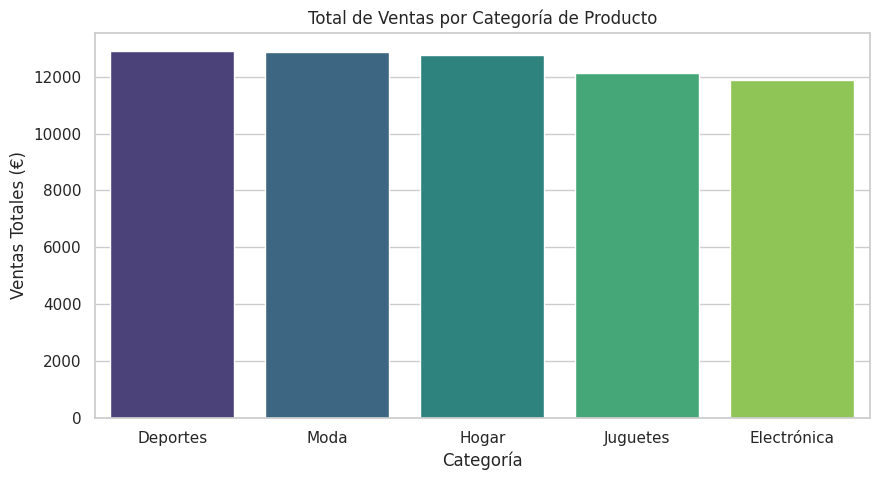

Análisis: La categoría líder es 'Deportes', mientras que la que genera menos ingresos es 'Electrónica'.


In [236]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configuración estética global
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Comportamiento de categorías
ventas_categoria = df.groupby('Categoria_Producto')['Monto_Venta'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=ventas_categoria, x='Categoria_Producto', y='Monto_Venta', palette='viridis', hue='Categoria_Producto', legend=False)
plt.title('Total de Ventas por Categoría de Producto')
plt.ylabel('Ventas Totales (€)')
plt.xlabel('Categoría')
plt.show()

categoria_lider = ventas_categoria.iloc[0]['Categoria_Producto']
categoria_menor = ventas_categoria.iloc[-1]['Categoria_Producto']
print(f"Análisis: La categoría líder es '{categoria_lider}', mientras que la que genera menos ingresos es '{categoria_menor}'.")

**Análisis**: La categoría líder es `Deportes`, mientras que la que genera menos ingresos es `Electrónica`.

#### 4.2 Frecuencia de compras por rango de edades

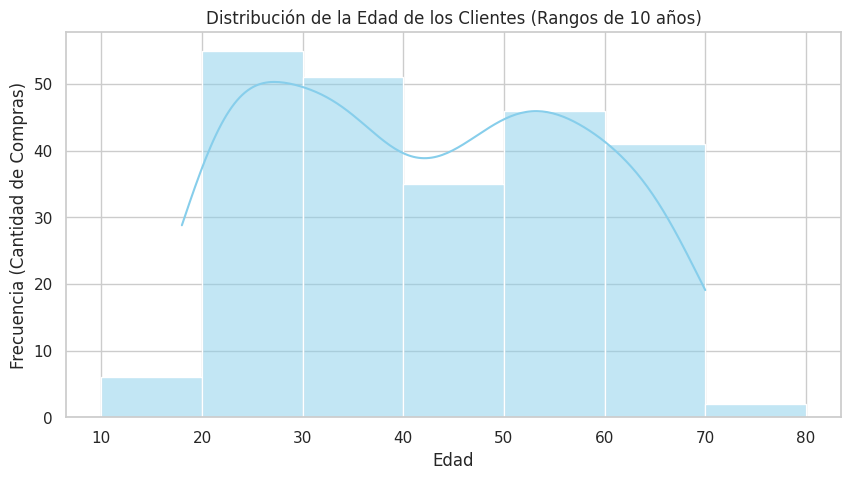

In [237]:
# 2. Perfil del consumidor: Histograma de Edad con rangos cerrados (bins de 10 años)
plt.figure(figsize=(10, 5))
bins_definidos = range(10, 90, 10)
plot_data = df['Edad_Cliente'].dropna()
sns.histplot(plot_data,bins=bins_definidos, kde=True, color='skyblue')

plt.title('Distribución de la Edad de los Clientes (Rangos de 10 años)')
plt.xlabel('Edad')
plt.ylabel('Frecuencia (Cantidad de Compras)')
plt.xticks(bins_definidos)
plt.show()


**Análisis**: El histograma muestra frecuencia de cantidad de compras por rangos de edad. Esto permite identificar con precisión el segmento de mercado principal: El rango de **20 a 30 años** es el segmento que más cantidad de compras realiza, seguido por el segmento de 30 a 40 años

#### 4.3 Preferencias de pago por Ciudad

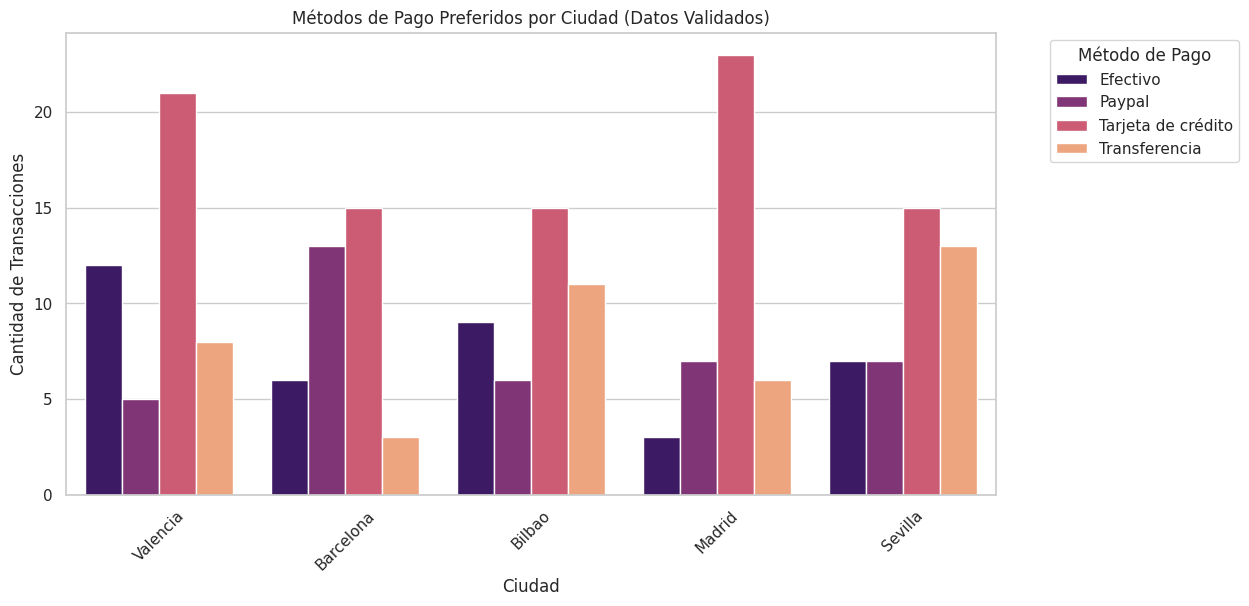

In [238]:
# 3. Preferencias de pago por Ciudad (Filtrando 'No especificado')
df_geografico = df[df['Ciudad'] != 'No especificado']

plt.figure(figsize=(12, 6))
sns.countplot(data=df_geografico, x='Ciudad', hue='Metodo_Pago', palette='magma')
plt.title('Métodos de Pago Preferidos por Ciudad (Datos Validados)')
plt.xlabel('Ciudad')
plt.ylabel('Cantidad de Transacciones')
plt.xticks(rotation=45)
plt.legend(title='Método de Pago', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


**Análisis**: Al filtrar los datos no especificados, podemos observar las preferencias reales por ubicación. Por ejemplo, se puede ver que el método de pago `Tarjeta de Crédito` es predominante en todas las ciudades, con una tendencia marcada en ciudades como Valencia y Madrid.

#### 4.4 Tendencia de ventas por día

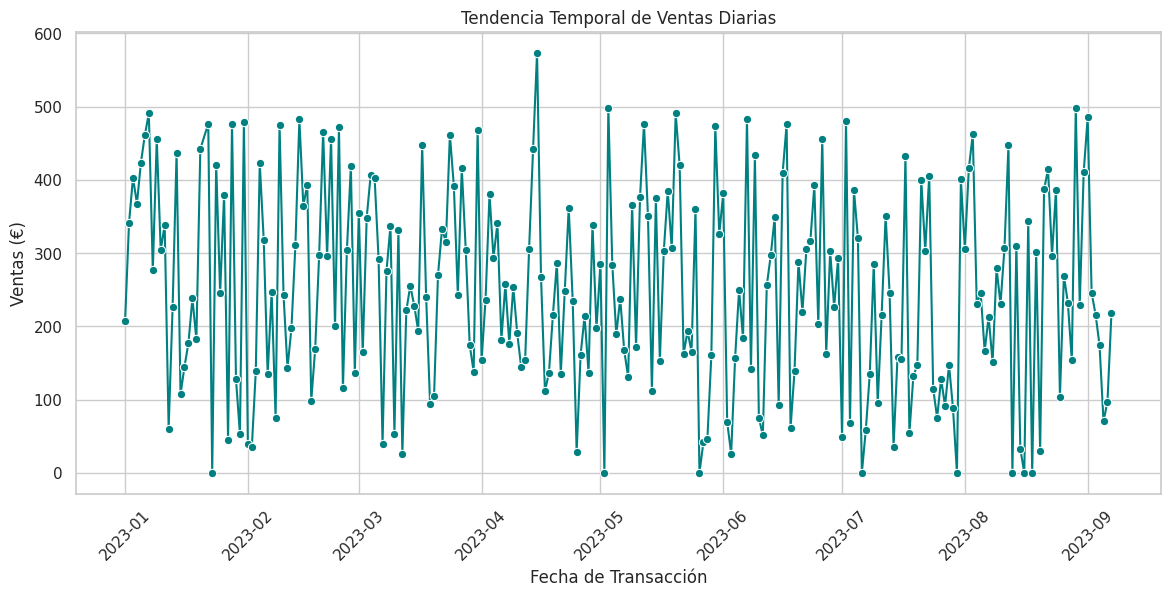

In [239]:
# 4. Tendencia temporal
ventas_diarias = df.groupby('Fecha')['Monto_Venta'].sum().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(data=ventas_diarias, x='Fecha', y='Monto_Venta', marker='o', color='teal')
plt.title('Tendencia Temporal de Ventas Diarias')
plt.ylabel('Ventas (€)')
plt.xlabel('Fecha de Transacción')
plt.xticks(rotation=45)
plt.show()


**Análisis**: Se observa que existen picos de ventas en días específicos del mes. Sin embargo, el tipo de gráfico dificulta identificar cuáles días podrían ser los de mayor venta. Se propone entonces un gráfico radial.

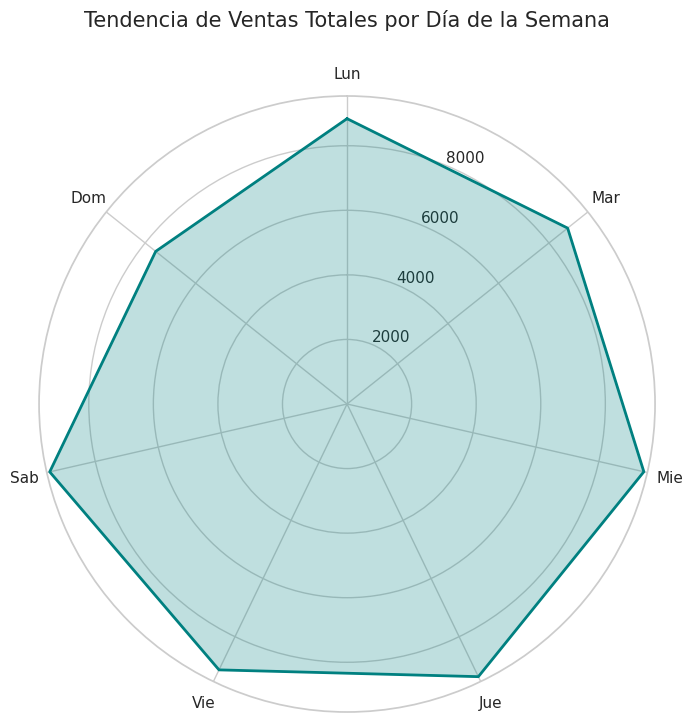

Análisis: El día con mayor volumen de ventas es: Sábado.


In [240]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Preparar los datos por día de la semana
df['Dia_Semana'] = df['Fecha'].dt.day_name()
dias_ordenados = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dict_dias = {'Monday': 'Lunes', 'Tuesday': 'Martes', 'Wednesday': 'Miércoles', 'Thursday': 'Jueves', 'Friday': 'Viernes','Saturday':'Sábado','Sunday':'Domingo'}

# Calcular ventas totales por día
ventas_dia = df.groupby('Dia_Semana')['Monto_Venta'].sum().reindex(dias_ordenados).fillna(0)

# 2. Configuración del gráfico radial
labels = ['Lun', 'Mar', 'Mie', 'Jue', 'Vie', 'Sab', 'Dom']
stats = ventas_dia.values.tolist()

# El gráfico radial debe cerrarse, por lo que repetimos el primer valor al final
stats += stats[:1]
angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]

# 3. Dibujar
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw=dict(polar=True))
ax.fill(angles, stats, color='teal', alpha=0.25)
ax.plot(angles, stats, color='teal', linewidth=2)

# Ajustar etiquetas de los días
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), labels)

plt.title('Tendencia de Ventas Totales por Día de la Semana', size=15, y=1.1)
plt.show()

# Hallazgo
dia_max = ventas_dia.idxmax()
dict_dias.values()
print(f"Análisis: El día con mayor volumen de ventas es: {dict_dias[dia_max]}.")

**Análisis:** Se puede ver a partir del gráfico radial que el día con mayor volumen de ventas es el **sábado**. Aunque la distribución para los otros días es relativamente uniforme, hay una evidente *disminución* los días **domingo**.



## 5. Conclusiones
1. **Calidad de Datos**: La limpieza inicial fue crítica; ignorar duplicados y outliers habría inflado las ventas totales en más de €87,000.
2. **Oportunidad de Mercado**: Las campañas de marketing deben enfocarse en jóvenes de 20-30 años, preferiblemente los días sábados.
3. **Estrategia Geográfica**: Se recomienda fortalecer las pasarelas de pago con tarjeta en Madrid y Valencia, donde el volumen de transacciones es mayor.